In [1]:
%matplotlib inline
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.linalg as la
sns.set(style='whitegrid')
from sklearn.decomposition import PCA
from sklearn.preprocessing import scale

#pd.options.display.float_format = '{:.2f}'.format    # pandas: para todos os números aparecerem com duas casas decimais
#np.set_printoptions(precision=2, suppress=True)      # numpy: para todos os números aparecerem com duas casas decimais

# Exemplo 1

Dados de doze empresas e 3 variáveis - exemplo de MINGOTI (2005).

Vamos criar o dataframe usando a funçao DataFrame do pandas. Poderíamos também ter os dados salvos em uma planilha e usar a função read_csv para lê-las.



*   B: Ganho bruto
*   L: Ganho líquido
*   P: Patrimônio acumulado







In [2]:
emp=pd.DataFrame({'B':[9893,8776,13572,6455,5129,5432,3807,3423,3708,3294,5433,6287],
                  'L':[564,384,1103,743,203,215,385,187,127,297,432,451],
                  'P':[17689,17359,18597,8745,14397,3467,4679,6754,2275,6754,5589,8972]})
print(emp)

        B     L      P
0    9893   564  17689
1    8776   384  17359
2   13572  1103  18597
3    6455   743   8745
4    5129   203  14397
5    5432   215   3467
6    3807   385   4679
7    3423   187   6754
8    3708   127   2275
9    3294   297   6754
10   5433   432   5589
11   6287   451   8972


In [3]:
#Observando as medidas resumo das variáveis
emp.describe()

,B,L,P
count,12.000000,12.000000,12.000000
mean,6267.416667,424.250000,9606.416667
std,3090.405900,276.231828,5865.842906
min,3294.000000,127.000000,2275.000000
25%,3782.250000,212.000000,5361.500000
50%,5432.500000,384.500000,7749.500000
75%,7035.250000,479.250000,15137.500000
max,13572.000000,1103.000000,18597.000000


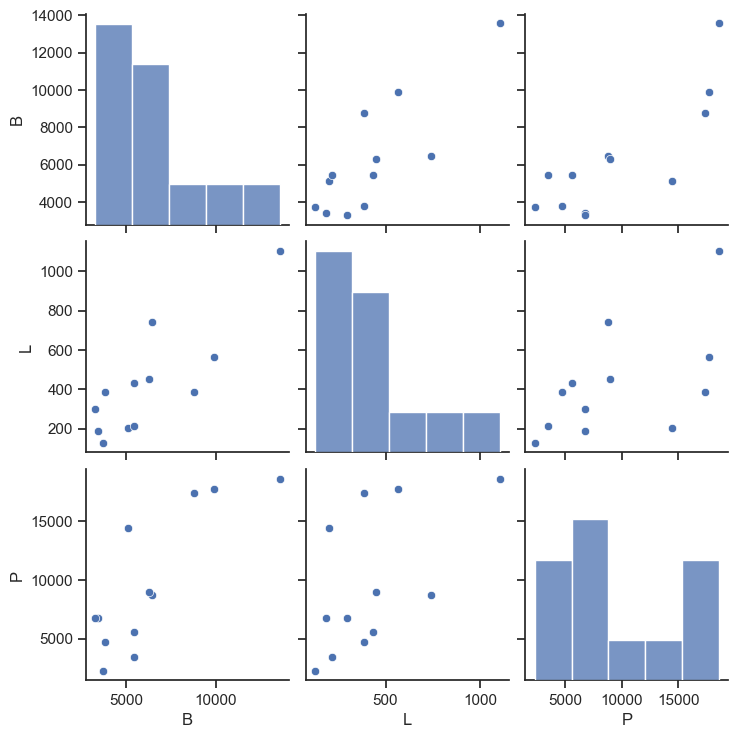

In [4]:
#Verificando se as variáveis são correlacionadas
sns.set(style='ticks')
sns.pairplot(emp);

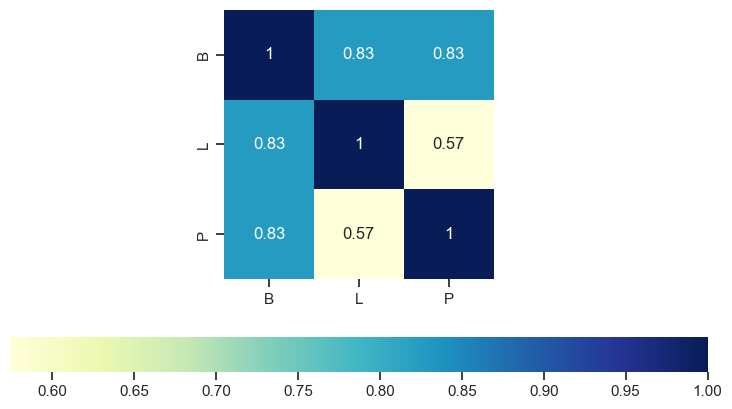

In [5]:
plt.figure(figsize=(9,5))
ax=sns.heatmap(emp.corr(),
               annot=True,
               cmap='YlGnBu',
               cbar_kws={"orientation":"horizontal"})
ax.set_aspect("equal")

## Análise de Componentes Principais

In [6]:
pca=PCA()
resultado_pca=pca.fit_transform(scale(emp))
resultado=pd.DataFrame({'cp1':resultado_pca[:,0],'cp2':resultado_pca[:,1],'cp3':resultado_pca[:,2]})

In [7]:
#coeficientes dos CPs (autovetores)
#cada linha é um CP
pca.components_

array([[ 6.16984432e-01,  5.56411204e-01,  5.56540010e-01],
       [ 4.96177686e-04, -7.07463505e-01,  7.06749704e-01],
       [ 7.86975199e-01, -4.35777422e-01, -4.36770047e-01]])

Os componentes principais obtidos a partir da matriz R forma:

Y1=0,62*Z1+0,56*Z2+0,56*Z3

Y2=-0,00*Z1-0,71*Z2+0,71*Z3

Y3=0,79*Z1-0,44*Z2-0,43*Z3

em que:

Z1: B padronizada

Z2: L padronizada

Z3: P padronizada

In [8]:
# variância explicada dos CPs
pca.explained_variance_ratio_

array([0.83001946, 0.14193416, 0.02804639])

In [9]:
#variância explicada acumulada
np.cumsum(np.round(pca.explained_variance_ratio_,decimals=4)*100)

array([83.  , 97.19, 99.99])

As variâncias explicadas dos componentes principais são:

V(Y1)=83%

V(Y2)=14,2%

V(Y3)=2,8%

In [10]:
# escores dos  CPs: Y=e.T*X
resultado

,cp1,cp2,cp3
0,1.850989,0.643914,0.105453
1,1.206673,1.083699,0.130615
2,3.842103,-0.683032,0.125232
3,0.624356,-0.961030,-0.408328
4,-0.228132,1.194516,-0.310798
5,-1.222833,-0.212999,0.600055
6,-1.083921,-0.515500,-0.206525
7,-1.374931,0.275211,-0.143784
8,-1.885589,-0.127892,0.379218
9,-1.170406,-0.019061,-0.359345


## Análise Gráfica dos Componentes

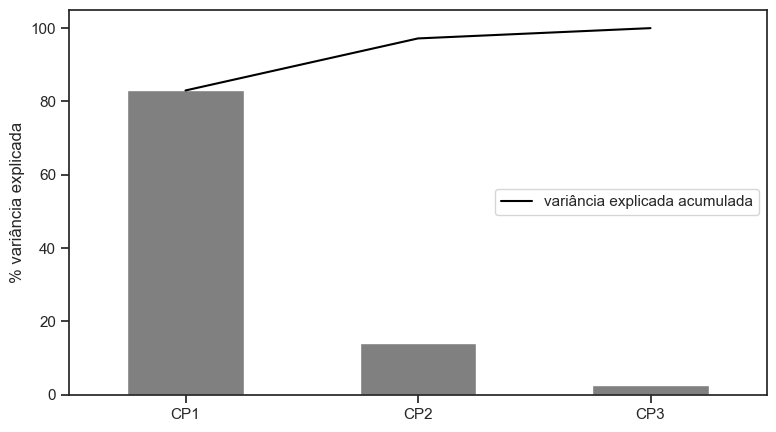

In [11]:
#Gráfico da variância acumulada
# variâncias acumuladas
tot = sum(pca.explained_variance_)
var_exp = [(i / tot)*100 for i in sorted(pca.explained_variance_, reverse=True)]
cum_var_exp = np.cumsum(var_exp)
# número de CPs gerados (k = p)
cp =['CP'+str(i+1) for i in range(len(pca.components_))]
# dataframe com as variâncias acumuladas para criar o scree plot
df = pd.DataFrame({'cp': cp, 'var_exp': var_exp, 'cum_var_exp': cum_var_exp})
# scree plot com %
fig, ax = plt.subplots(figsize=(9,5))
df.plot.bar('cp', 'var_exp', color='gray', ax=ax, legend=False)
df.plot.line('cp', 'cum_var_exp', color='black', ax=ax)
plt.legend(labels=['variância explicada acumulada'],
           loc='center right',)
plt.ylabel('% variância explicada')
plt.xlabel('');

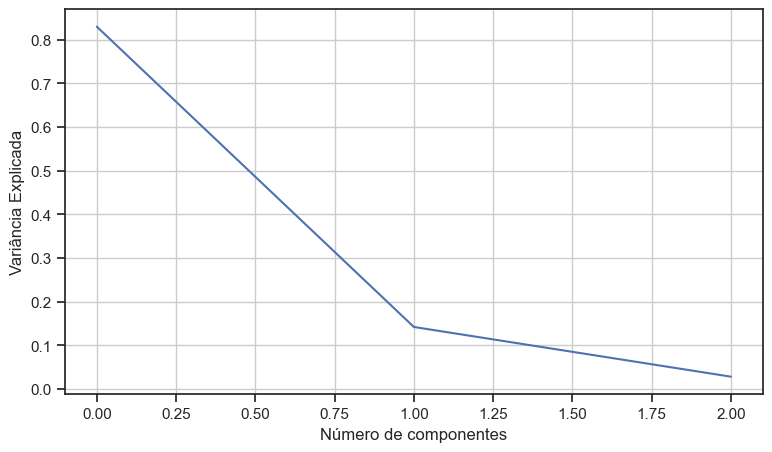

In [12]:
plt.figure(figsize=(9,5))
plt.plot(pca.explained_variance_ratio_)
plt.xlabel('Número de componentes')
plt.ylabel('Variância Explicada')
plt.grid()
plt.show()

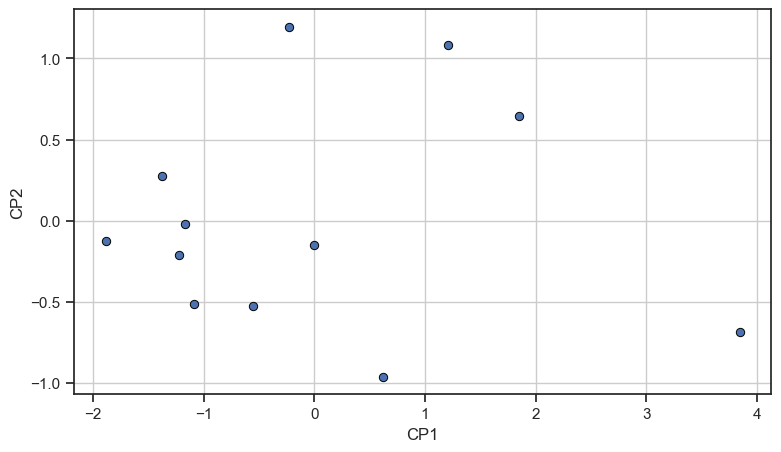

In [13]:
#diagrama de dispersão entre CP1 e CP2
plt.figure(figsize=(9,5))
plt.scatter(resultado_pca[:, 0], resultado_pca[:, 1], edgecolors='black', linewidths=.7);
plt.xlabel('CP1')
plt.ylabel('CP2')
plt.grid();

## Efeito das variáveis em cada componente

O atributo components_ nos dá os autovetores, que representam a direção de máxima variância dos dados. Ao verificar a correlação dos componentes com as variávies originais podemos ver a influência que cada variável tem sobre os componentes.

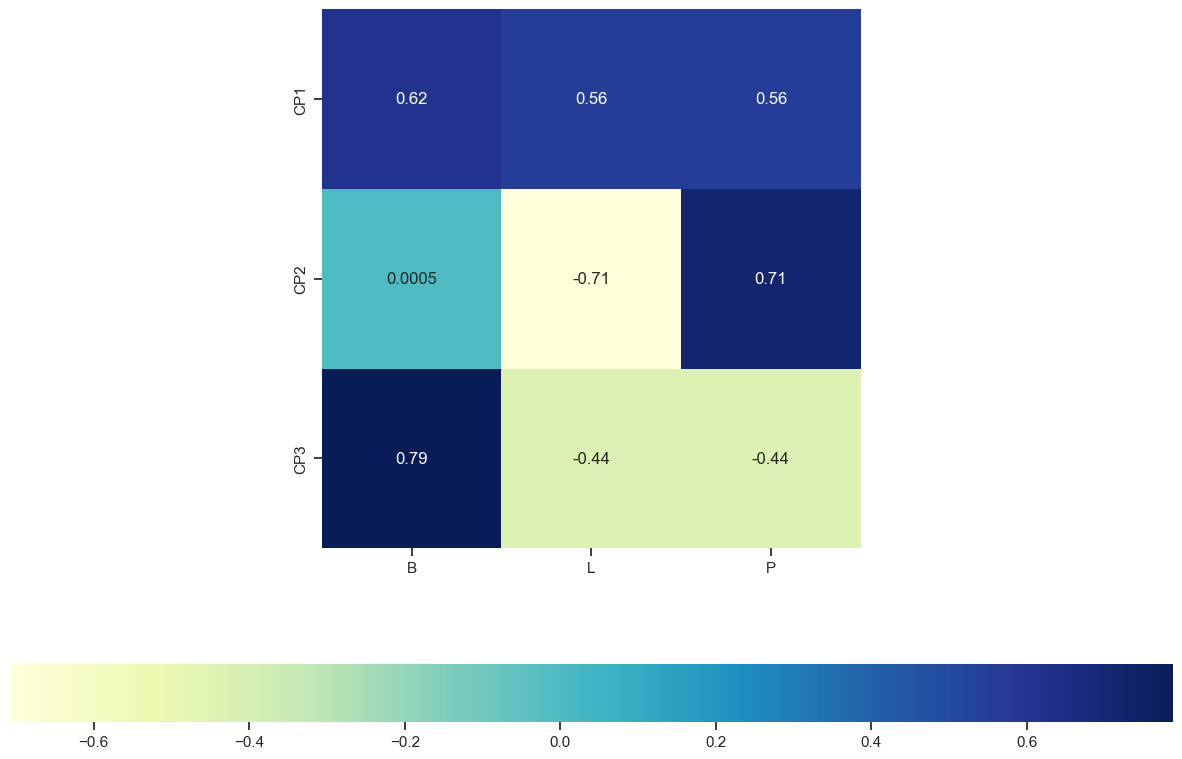

In [14]:
plt.figure(figsize=(15,10))
ax = sns.heatmap(pca.components_,
                 annot=True,
                 cmap='YlGnBu',
                 yticklabels=['CP'+str(i+1) for i in range(len(pca.components_))],
                 xticklabels=emp.columns,
                 cbar_kws={"orientation": "horizontal"})
ax.set_aspect("equal")


**Interpretação dos Componentes Principais**

Y1: índice de desempenho global da empresa (valores altos positivos indicam empresas que tiveram ganhos B, L e P maiores do que a média)

Y2: comparação entre L e P (valores 0 indicam empresas em que L está em equilíbrio com P)

Y3: comparação de B com o índice composto por L e P
(representa pouco da variação total, mas pode ser de interesse para o pesquisador)

##Biplot

Biplot é um gráfico interessante e contém muitas informações úteis.

Ele contém dois gráficos:

Gráfico de dispersão do ACP * que mostra os dois primeiros componentes (já traçamos isso acima)
Gráfico de autovetores do ACP * que mostra a intensidade com que cada característica influencia um componente principal.
PCA Loading Plot: Todos os vetores começam na origem e seus valores projetados nos componentes explicam quanto peso eles têm naquele componente. Além disso, os ângulos entre vetores individuais informam sobre a correlação entre eles.

Mais sobre o biplot [aqui] (http://www.nonlinear.com/support/progenesis/comet/faq/v2.0/pca.aspx)

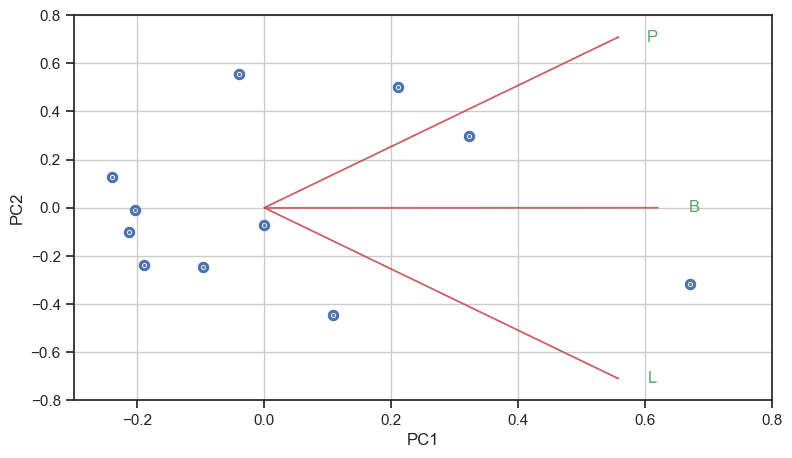

In [15]:
fig, ax = plt.subplots(figsize=(9,5))
def myplot(score,coeff,labels=None):
    xs = score[:,0]
    ys = score[:,1]
    n = coeff.shape[0]
    scalex = 1.0/(xs.max() - xs.min())
    scaley = 1.0/(ys.max() - ys.min())
    plt.scatter(xs * scalex, ys * scaley,s=5, linewidths = 6)
    for i in range(n):
        plt.arrow(0, 0, coeff[i,0], coeff[i,1],color = 'r',alpha = 0.8)
        if labels is None:
            plt.text(coeff[i,0]* 1.1, coeff[i,1] * 1, "Var"+str(i+1), color = 'green', ha = 'center', va = 'center')
        else:
            plt.text(coeff[i,0]* 1.1, coeff[i,1] * 1, labels[i], color = 'g', ha = 'center', va = 'center')

    plt.xlabel("PC{}".format(1))
    plt.ylabel("PC{}".format(2))
    ax.set(xlim=(-0.3, 0.8), ylim=(-0.8, 0.8))
    plt.grid()

myplot(resultado_pca[:,0:2],np.transpose(pca.components_[0:2, :]),labels=emp.columns)
plt.show()

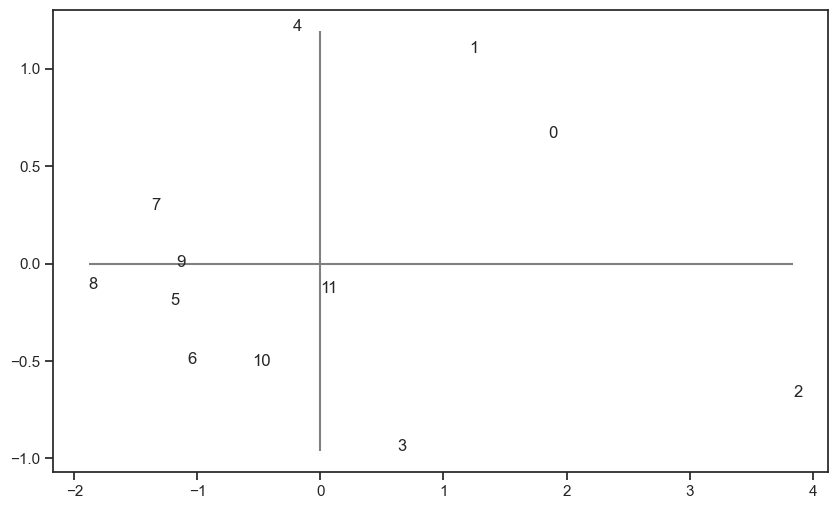

In [16]:
fig, ax = plt.subplots()
fig.set_size_inches(10, 6)
ax.scatter(resultado.cp1, resultado.cp2, s=0)
for i, txt in enumerate(resultado.index):
    ax.annotate(txt, (resultado.cp1[i], resultado.cp2[i]))
plt.hlines(0, resultado_pca[:, 0].min(), resultado_pca[:, 0].max(), color='gray')
plt.vlines(0, resultado_pca[:, 1].min(), resultado_pca[:, 1].max(), color='gray');

# Exemplo 2

### Dados de poluição do ar

- $SO2$: teor de SO2 do ar em microgramas por metro cúbico;
- $temp$: temperatura média anual em graus Fahrenheit;
- $manu$: número de empresas industriais que empregam 20 ou mais trabalhadores;
- $popul$: tamanho da população (censo de 1970) em milhares;
- $wind$: velocidade média anual do vento em milhas por hora;
- $precip$: precipitação média anual em polegadas;
- $predays$: número médio de dias com precipitação por ano.

In [17]:
# leitura do conjunto de dados
air  = pd.read_csv('https://patriciasiqueira.github.io/arquivos/air.csv', index_col='city')

In [18]:
air.head(10)

,SO2,temp,manu,popul,wind,precip,predays
city,,,,,,,
Albany,46,47.6,44,116,8.8,33.36,135
Albuquerque,11,56.8,46,244,8.9,7.77,58
Atlanta,24,61.5,368,497,9.1,48.34,115
Baltimore,47,55.0,625,905,9.6,41.31,111
Buffalo,11,47.1,391,463,12.4,36.11,166
Charleston,31,55.2,35,71,6.5,40.75,148
Chicago,110,50.6,3344,3369,10.4,34.44,122
Cincinnati,23,54.0,462,453,7.1,39.04,132
Cleveland,65,49.7,1007,751,10.9,34.99,155


In [19]:
# nomear o conjunto de dados como X
X = air

Usaremos a matriz de correlações **R**

In [20]:
# autovalores e autovetores de R
R = X.corr()
l, e = np.linalg.eig(R)
idx = np.argsort(l)[::-1]
l = l[idx]
e = e[:,idx]
print(l)
print(e)

[2.72811968 1.51233485 1.39497299 0.89199129 0.34677866 0.10028759
 0.02551493]
[[ 4.89698817e-01  8.45756306e-02 -1.43501956e-02 -4.04210075e-01
  -7.30394180e-01  1.83345726e-01 -1.49529278e-01]
 [-3.15370690e-01 -8.86378850e-02 -6.77136178e-01  1.85227939e-01
  -1.62465152e-01  6.10661071e-01  2.36641125e-02]
 [ 5.41168703e-01 -2.25881089e-01 -2.67159129e-01  2.62723671e-02
   1.64101110e-01 -4.27335187e-02  7.45180920e-01]
 [ 4.87588112e-01 -2.82003804e-01 -3.44837959e-01  1.13403769e-01
   3.49104824e-01 -8.78632695e-02 -6.49125507e-01]
 [ 2.49874928e-01  5.54714865e-02  3.11265456e-01  8.61901314e-01
  -2.68254900e-01  1.50053780e-01 -1.57653766e-02]
 [ 1.87312186e-04  6.25879366e-01 -4.92036299e-01  1.83937185e-01
  -1.60598783e-01 -5.53573845e-01  1.03153086e-02]
 [ 2.60179073e-01  6.77967410e-01  1.09578949e-01 -1.09760698e-01
   4.39969776e-01  5.04946685e-01 -8.21739320e-03]]


Análise exploratória:

In [21]:
X.describe()

,SO2,temp,manu,popul,wind,precip,predays
count,41.000000,41.000000,41.000000,41.000000,41.000000,41.000000,41.000000
mean,30.048780,55.763415,463.097561,608.609756,9.443902,36.769024,113.902439
std,23.472272,7.227716,563.473948,579.113023,1.428644,11.771550,26.506419
min,8.000000,43.500000,35.000000,71.000000,6.000000,7.050000,36.000000
25%,13.000000,50.600000,181.000000,299.000000,8.700000,30.960000,103.000000
50%,26.000000,54.600000,347.000000,515.000000,9.300000,38.740000,115.000000
75%,35.000000,59.300000,462.000000,717.000000,10.600000,43.110000,128.000000
max,110.000000,75.500000,3344.000000,3369.000000,12.700000,59.800000,166.000000


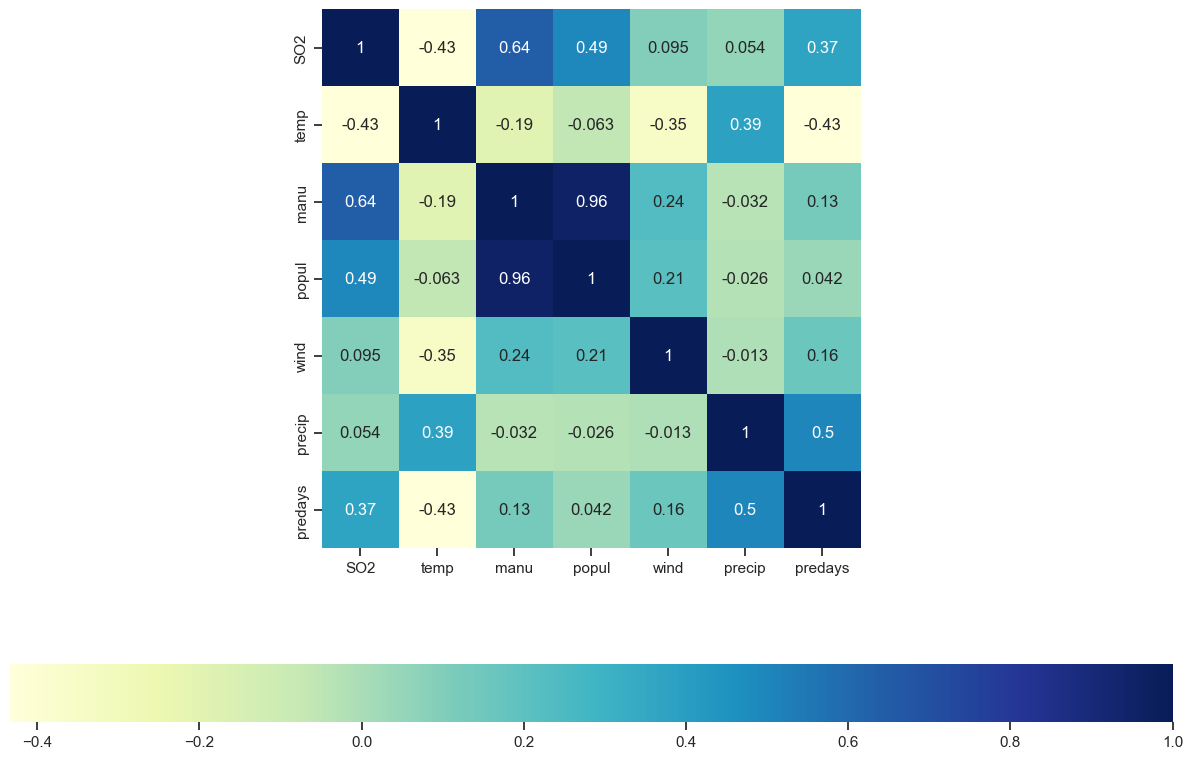

In [22]:
plt.figure(figsize=(15,10))
ax = sns.heatmap(X.corr(),
                 annot=True,
                 cmap='YlGnBu',
                 cbar_kws={"orientation": "horizontal"})
ax.set_aspect("equal")

Quais as variáveis são mais correlacionadas? E menos?


* As variávais populacão e manufatura são as mais correlacionadas.

* As variáveis precipitação e manufatura são as menos correlacionadas.


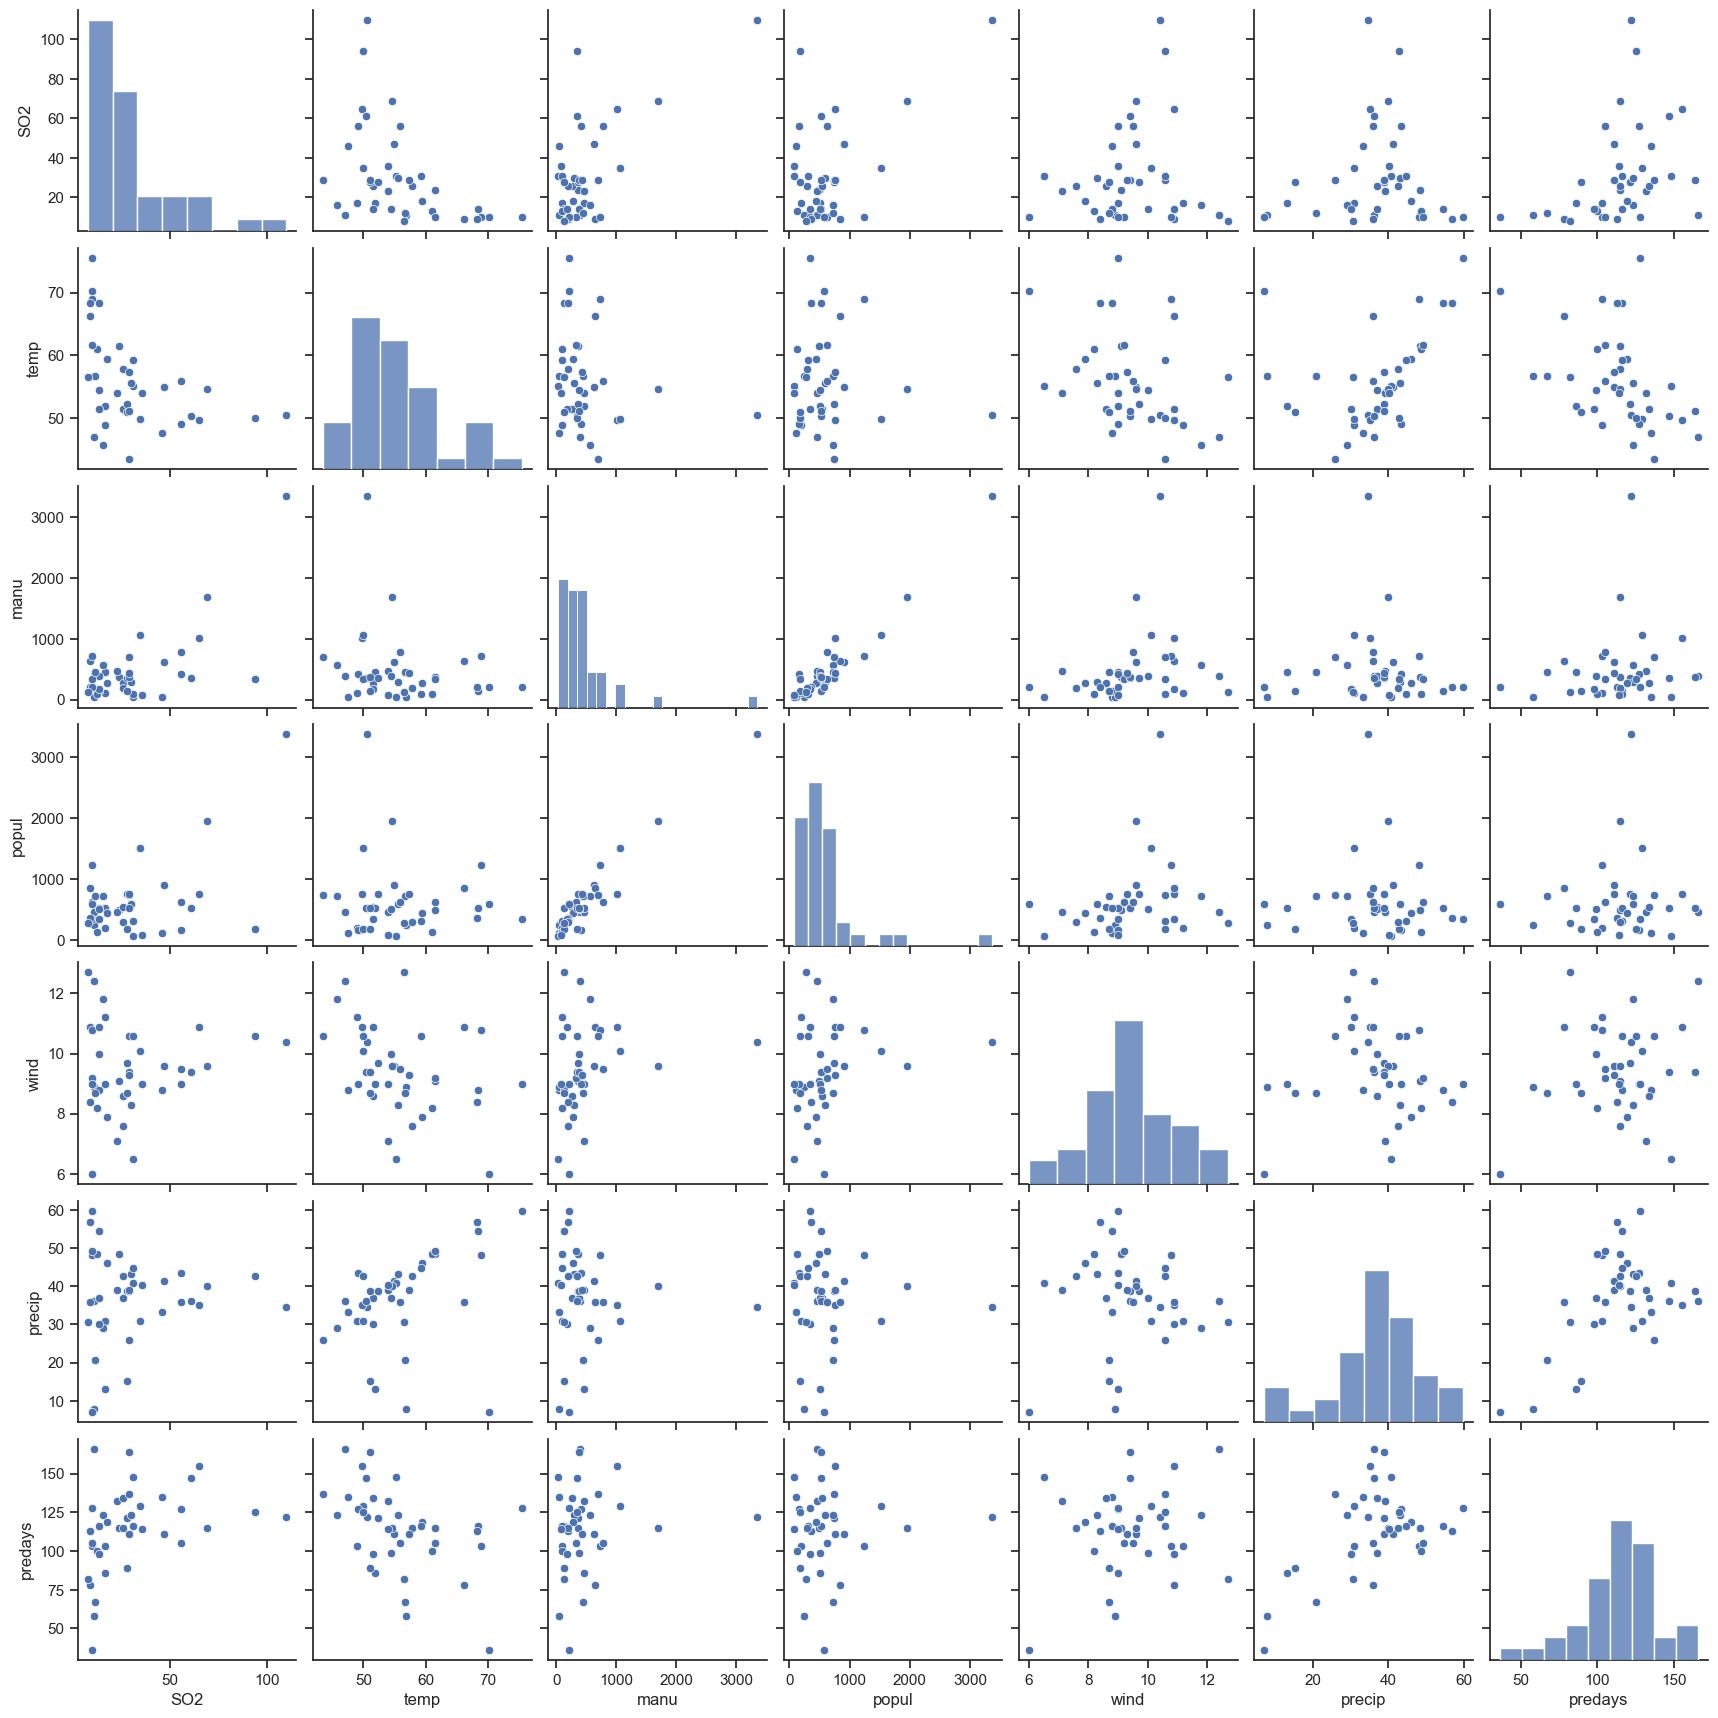

In [23]:
sns.set(style='ticks')
sns.pairplot(X);

Obtenção dos componentes principais (usando *scikit-learn*)

In [24]:
# X = air.iloc[:,1:]  # se quisermos selecionar variáveis
X = air

In [25]:
# aplicar ACP usando a matriz de correlações
pca = PCA()
resultado_pca = pca.fit_transform(scale(X))   # scale(X) padroniza os dados, como se usássemos a matriz R

In [26]:
# coeficientes dos CPs (autovetores)
# cada linha é um CP
pca.components_

array([[ 4.89698817e-01, -3.15370690e-01,  5.41168703e-01,
         4.87588112e-01,  2.49874928e-01,  1.87312186e-04,
         2.60179073e-01],
       [-8.45756306e-02,  8.86378850e-02,  2.25881089e-01,
         2.82003804e-01, -5.54714865e-02, -6.25879366e-01,
        -6.77967410e-01],
       [ 1.43501956e-02,  6.77136178e-01,  2.67159129e-01,
         3.44837959e-01, -3.11265456e-01,  4.92036299e-01,
        -1.09578949e-01],
       [-4.04210075e-01,  1.85227939e-01,  2.62723671e-02,
         1.13403769e-01,  8.61901314e-01,  1.83937185e-01,
        -1.09760698e-01],
       [ 7.30394180e-01,  1.62465152e-01, -1.64101110e-01,
        -3.49104824e-01,  2.68254900e-01,  1.60598783e-01,
        -4.39969776e-01],
       [ 1.83345726e-01,  6.10661071e-01, -4.27335187e-02,
        -8.78632695e-02,  1.50053780e-01, -5.53573845e-01,
         5.04946685e-01],
       [ 1.49529278e-01, -2.36641125e-02, -7.45180920e-01,
         6.49125507e-01,  1.57653766e-02, -1.03153086e-02,
         8.2173932

In [27]:
# variâncias explicadas dos CPs
pca.explained_variance_ratio_

array([0.38973138, 0.21604784, 0.19928186, 0.12742733, 0.04953981,
       0.0143268 , 0.00364499])

In [28]:
# variância explicada acumulada
np.cumsum(np.round(pca.explained_variance_ratio_, decimals=4)*100)

array([38.97, 60.57, 80.5 , 93.24, 98.19, 99.62, 99.98])

In [29]:
# os três primeiros CPs
print(pca.components_[0:3, :])

[[ 4.89698817e-01 -3.15370690e-01  5.41168703e-01  4.87588112e-01
   2.49874928e-01  1.87312186e-04  2.60179073e-01]
 [-8.45756306e-02  8.86378850e-02  2.25881089e-01  2.82003804e-01
  -5.54714865e-02 -6.25879366e-01 -6.77967410e-01]
 [ 1.43501956e-02  6.77136178e-01  2.67159129e-01  3.44837959e-01
  -3.11265456e-01  4.92036299e-01 -1.09578949e-01]]


In [30]:
X.columns

Index(['SO2', 'temp', 'manu', 'popul', 'wind', 'precip', 'predays'], dtype='object')

### Efeito das variaveis em cada componente

O atributo 'components_' nos dá os autovetores que representam a direção de máxima variância dos dados. Ao verificar a correlação dos componentes com as variáveis originais podemos ver a influência que cada variável tem sobre os componentes.

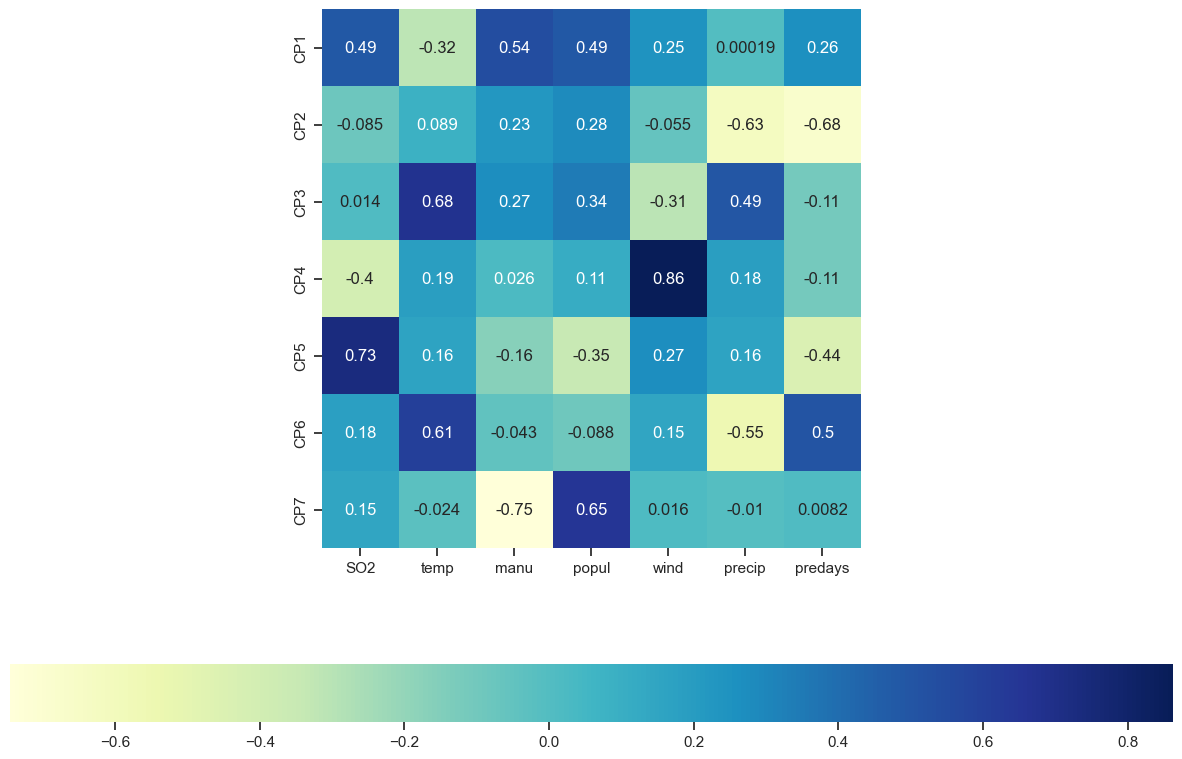

In [31]:
plt.figure(figsize=(15,10))
ax = sns.heatmap(pca.components_,
                 annot=True,
                 cmap='YlGnBu',
                 yticklabels=[ "CP"+str(X) for X in range(1,pca.n_components_+1)],
                 xticklabels=list(X.columns),
                 cbar_kws={"orientation": "horizontal"})
ax.set_aspect("equal")

Interpretação:

- Y1: índice global de qualidade de vida - escores altos indicam cidades com maior concentração de S02, com mais fábricas, mais gente, mais vento, mais dias chuvosos, temp. baixas
- Y2: índice de chuvas - escores altos negativos indicam cidades chuvosas
- Y3: leva em conta chuvas e temperatura - altos valores para cidades quentes e úmidas e baixos para frias e secas

In [32]:
# escores dos dois primeiros CPs
resultado = pd.DataFrame({'cp1':resultado_pca[:, 0], 'cp2':resultado_pca[:, 1]}, index=X.index)
resultado

,cp1,cp2
city,,
Albany,-0.034285,-0.910007
Albuquerque,-1.816821,2.763310
Atlanta,-0.618589,-0.638089
Baltimore,0.800713,-0.034900
Buffalo,0.827309,-1.568931
Charleston,-1.011927,-1.430787
Chicago,7.320800,2.052442
Cincinnati,-0.439862,-0.572089
Cleveland,2.322557,-0.937548


## Análise gráfica dos componentes

### Gráfico da variância acumulada

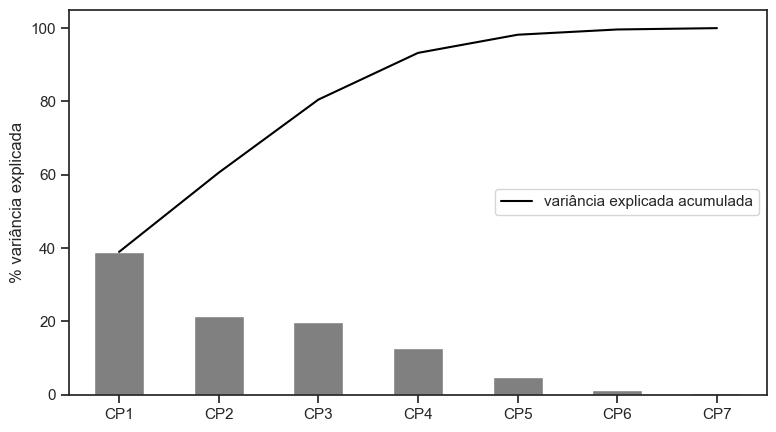

In [33]:
# variâncias acumuladas
tot = sum(pca.explained_variance_)
var_exp = [(i / tot)*100 for i in sorted(pca.explained_variance_, reverse=True)]
cum_var_exp = np.cumsum(var_exp)
# número de CPs gerados (k = p)
cp =['CP'+str(i+1) for i in range(len(pca.components_))]
# dataframe com as variâncias acumuladas para criar o scree plot
df = pd.DataFrame({'cp': cp, 'var_exp': var_exp, 'cum_var_exp': cum_var_exp})
# scree plot com %
fig, ax = plt.subplots(figsize=(9,5))
df.plot.bar('cp', 'var_exp', color='gray', ax=ax, legend=False)
df.plot.line('cp', 'cum_var_exp', color='black', ax=ax)
plt.legend(labels=['variância explicada acumulada'],
           loc='center right',)
plt.ylabel('% variância explicada')
plt.xlabel('');

### *Scree plot*

O *Scree plot* é um gráfico com os autovalores de cada componente

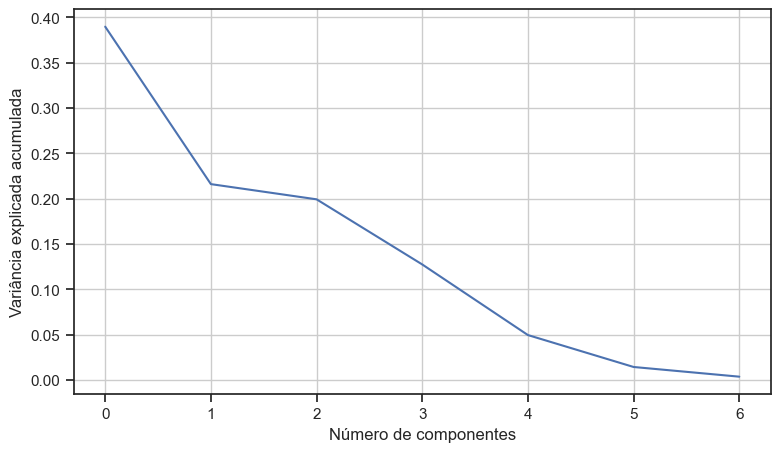

In [34]:
plt.figure(figsize=(9,5))
plt.plot(pca.explained_variance_ratio_)
plt.xlabel('Número de componentes')
plt.ylabel('Variância explicada acumulada')
plt.grid()
plt.show()

É possível ver pelo gráfico que o primeiro componente explica quase  $40\%$ da variância dos dados.

### Diagrama de dispersão entre CP1 e CP2

Nesse gráfico vamos visualizar a relação entre os dois primeiros CPs.

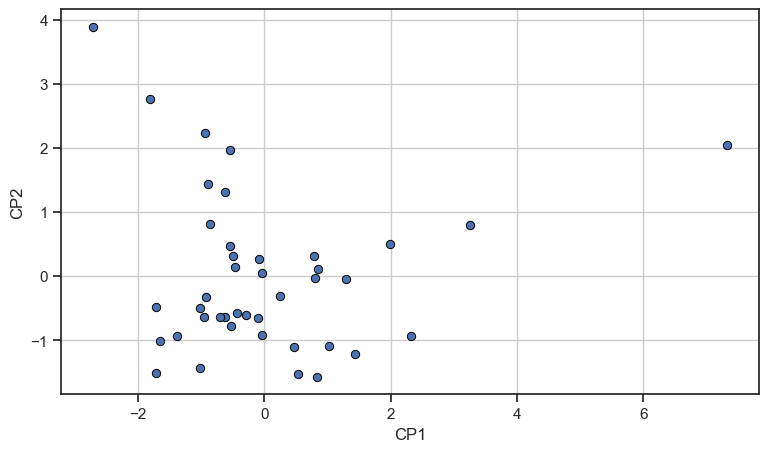

In [35]:
plt.figure(figsize=(9,5))
plt.scatter(resultado_pca[:, 0], resultado_pca[:, 1], edgecolors='black', linewidths=.7);
plt.xlabel('CP1')
plt.ylabel('CP2')
plt.grid();

### ACP *Biplot*

Biplot é um gráfico interessante e contém muitas informações úteis.

Ele contém dois gráficos:

1. * Gráfico de dispersão do ACP * que mostra os dois primeiros componentes (já traçamos isso acima)
2. * Gráfico de autovetores do ACP * que mostra a intensidade com que cada característica influencia um componente principal.

**PCA Loading Plot:** Todos os vetores começam na origem e seus valores projetados nos componentes explicam quanto peso eles têm naquele componente. Além disso, os ângulos entre vetores individuais informam sobre a correlação entre eles.

Mais sobre o biplot [aqui] (http://www.nonlinear.com/support/progenesis/comet/faq/v2.0/pca.aspx)

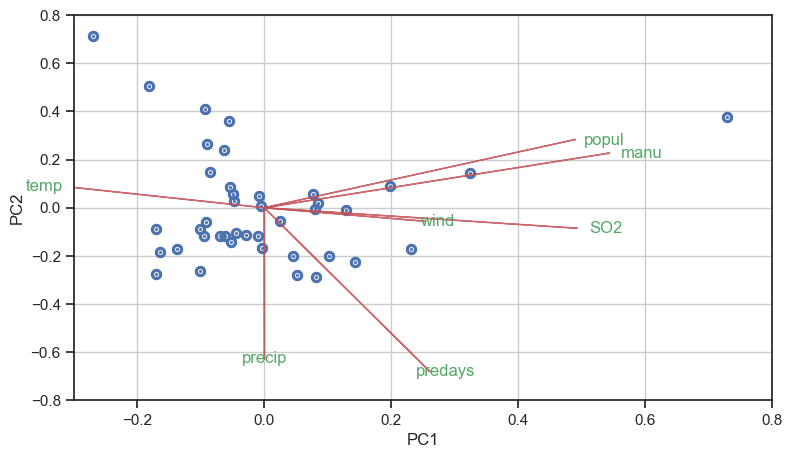

In [36]:
fig, ax = plt.subplots(figsize=(9,5))
def myplot(score,coeff,labels=None):
    xs = score[:,0]
    ys = score[:,1]
    n = coeff.shape[0]
    scalex = 1.0/(xs.max() - xs.min())
    scaley = 1.0/(ys.max() - ys.min())
    plt.scatter(xs * scalex, ys * scaley,s=5, linewidths = 6)
    for i in range(n):
        plt.arrow(0, 0, coeff[i,0], coeff[i,1],color = 'r',alpha = 0.8)
        if labels is None:
            plt.text(coeff[i,0]* 1.1, coeff[i,1] * 1, "Var"+str(i+1), color = 'green', ha = 'center', va = 'center')
        else:
            plt.text(coeff[i,0]* 1.1, coeff[i,1] * 1, labels[i], color = 'g', ha = 'center', va = 'center')

    plt.xlabel("PC{}".format(1))
    plt.ylabel("PC{}".format(2))
    ax.set(xlim=(-0.3, 0.8), ylim=(-0.8, 0.8))
    plt.grid()

myplot(resultado_pca[:,0:2],np.transpose(pca.components_[0:2, :]),list(X.columns))
plt.show()

/tmp/ipykernel_12924/3330573205.py:5: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  ax.annotate(txt, (resultado.cp1[i], resultado.cp2[i]))


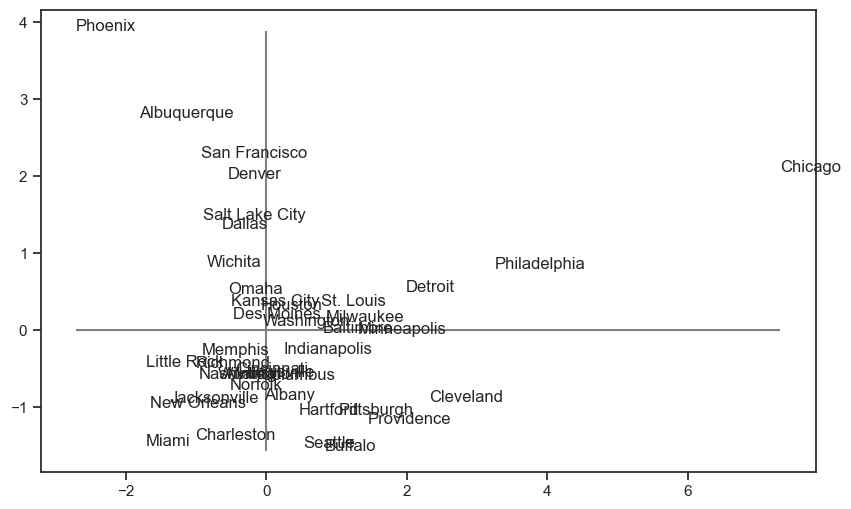

In [37]:
fig, ax = plt.subplots()
fig.set_size_inches(10, 6)
ax.scatter(resultado.cp1, resultado.cp2, s=0)
for i, txt in enumerate(resultado.index):
    ax.annotate(txt, (resultado.cp1[i], resultado.cp2[i]))
plt.hlines(0, resultado_pca[:, 0].min(), resultado_pca[:, 0].max(), color='gray')
plt.vlines(0, resultado_pca[:, 1].min(), resultado_pca[:, 1].max(), color='gray');

Exemplos:
- Chicago tem população alta, muitas fábricas e muito SO2, assim como Philadelphia e Detroit
- Cleveland, Providence, Buffalo são exemplos de cidades com muitas chuvas
- Charleston, Miami e Seattle: precipitação alta e não muita poluição
- Albuquerque, Phoenix, San Francisco apresentam menos pluviosidade
- Phoenix, Albuquerque, Miami: temperaturas mais altas e menor poluição

Verificando as cidades:

In [38]:
air

,SO2,temp,manu,popul,wind,precip,predays
city,,,,,,,
Albany,46,47.6,44,116,8.8,33.36,135
Albuquerque,11,56.8,46,244,8.9,7.77,58
Atlanta,24,61.5,368,497,9.1,48.34,115
Baltimore,47,55.0,625,905,9.6,41.31,111
Buffalo,11,47.1,391,463,12.4,36.11,166
Charleston,31,55.2,35,71,6.5,40.75,148
Chicago,110,50.6,3344,3369,10.4,34.44,122
Cincinnati,23,54.0,462,453,7.1,39.04,132
Cleveland,65,49.7,1007,751,10.9,34.99,155


Lembrando a interpretação já realizada:

- Y1: índice global de qualidade de vida - escores altos indicam cidades com maior concentração de S02, maiores, com mais fábricas, mais gente, mais vento, mais dias chuvosos, temp. baixas
- Y2: índice de chuvas - escores altos negativos indicam cidades chuvosas
- Y3: leva em conta chuvas e temperatura - altos valores para cidades quentes e úmidas e baixos para frias e secas